# Reproducible Vietnamese Fintech LDA + Complete Visualizations

**Pipeline:** flexible data import -> reproducible Vietnamese preprocessing -> LDA grid search -> C_V / UMass / Topic Diversity / IRBO -> selected model -> document-topic probabilities -> publication figures and interactive pyLDAvis.

**Visualizations included:** (1) four evaluation curves by K; (2) top-term probability bars for **every** topic; (3) seeded word clouds for **every** topic; (4) topic prevalence; (5) topic-by-year heatmap where dates are valid; (6) interactive **pyLDAvis** saved as HTML and shown inline. All static figures are saved as PNG.

**Comparability:** LDA and BERTopic must use the same documents, preprocessing, reference corpus, top-N, and evaluation settings. This notebook is independent of Google Drive, external helper modules, CUDA, and fixed row counts.

## 0. Dependencies (run once, then restart kernel only if required)

In [1]:
%pip install -q "gensim==4.4.0" "underthesea==9.5.0" "pyLDAvis==3.4.1" "wordcloud==1.9.6" "pandas>=2,<3" "numpy>=1.26,<3" "matplotlib>=3.8" "openpyxl>=3.1" "xlrd>=2.0" "pyarrow>=15"

Note: you may need to restart the kernel to use updated packages.


## 1. Configuration and reproducibility

In [2]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTHONHASHSEED"] = "42"  # For subprocesses; this does not reset the running interpreter hash seed.

import sys, json, hashlib, random, platform, re, unicodedata
from pathlib import Path
from importlib.metadata import version
from itertools import combinations
import math
import matplotlib.pyplot as plt
from matplotlib import font_manager
from wordcloud import WordCloud
import numpy as np
import pandas as pd
from IPython.display import display
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from underthesea import word_tokenize

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATASET_NAME = "Fintech8kk"
DATA_PATH = None  # e.g. "/kaggle/input/fintech8kk/fintech_news_final.csv"; None = auto-discover
DATA_FILENAME = "fintech_news_final.csv"  # auto-discovery filename, any CSV / Parquet / XLSX
TEXT_FIELD = "raw_article"  # "title", "snippet", "raw_article"; or a list of columns
ID_COLUMN = "url"  # set None to use stable row IDs
DATE_COLUMN = "pub_date"  # optional; not used in training
SAMPLE_N = None  # e.g. 200 for smoke test; None for all rows

OUTPUT_DIR = Path("/kaggle/working/lda_fintechnews" if Path("/kaggle/working").exists() else "./lda_fintechnews")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

K_VALUES = [5, 10, 15, 20, 25, 30,35,40,45,50]
TOP_WORDS = 20
CV_WINDOW = 110
IRBO_WEIGHT = 0.9
NO_BELOW, NO_ABOVE, KEEP_N = 5, 0.5, 30000
PASSES, ITERATIONS, CHUNKSIZE = 10, 100, 200
ALPHA, ETA = "auto", "auto"
STOPWORDS = set()  # insert the EXACT same stopwords as BERTopic, if used
REUSE_CHECKPOINTS = True

# Visualization options (all figures are exported even when SHOW_PLOTS=False)
SHOW_PLOTS = True
PLOT_DPI = 150
TOP_PLOT_WORDS = 12  # top words in each bar chart; evaluation still uses TOP_WORDS=20
TOPICS_PER_PAGE = 6
WORDCLOUD_WORDS = 50
TIME_FREQ = "Y"  # "Y" for year, "Q" for quarter, "M" for month
DAYFIRST = True  # useful for dates in DD/MM/YYYY format
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"

print("Python:", platform.python_version())
print({name: version(name) for name in ["gensim", "underthesea", "numpy", "pandas"]})

Python: 3.13.18
{'gensim': '4.4.0', 'underthesea': '9.5.0', 'numpy': '2.1.3', 'pandas': '2.3.3'}


## 2. Load input flexibly and preserve document IDs

In [3]:
def find_data_file(filename):
    roots = [Path("/kaggle/input"), Path("/datasets/christiannam/fintechnews-final/fintech_news_final.csv"), Path.cwd()]
    matches = sorted({p.resolve() for root in roots if root.exists() for p in root.rglob(filename) if p.is_file()})
    if not matches:
        raise FileNotFoundError(f"Cannot find {filename}. Set DATA_PATH explicitly.")
    if len(matches) > 1:
        raise ValueError(f"Multiple matching datasets: {matches}. Set DATA_PATH explicitly.")
    return matches[0]

DATA_PATH = Path(DATA_PATH) if DATA_PATH is not None else find_data_file(DATA_FILENAME)
suffix = DATA_PATH.suffix.lower()
if suffix == ".csv":
    df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    # df = df.sample(n=200, random_state=42).copy()
elif suffix in {".parquet", ".pq"}:
    df = pd.read_parquet(DATA_PATH).fillna("").astype(str)
elif suffix in {".xlsx", ".xls"}:
    df = pd.read_excel(DATA_PATH, dtype=str, keep_default_na=False).fillna("")
else:
    raise ValueError("Supported formats: CSV, Parquet, XLSX/XLS")

text_columns = [TEXT_FIELD] if isinstance(TEXT_FIELD, str) else list(TEXT_FIELD)
required = set(text_columns) | ({ID_COLUMN} if ID_COLUMN else set())
missing = required - set(df.columns)
if missing:
    raise KeyError(f"Missing columns: {sorted(missing)}")

raw_n = len(df)
df["text"] = df[text_columns].fillna("").astype(str).agg("\n".join, axis=1).str.strip()
if ID_COLUMN:
    df["doc_id"] = df[ID_COLUMN].fillna("").astype(str).str.strip()
    df = df.loc[df.doc_id.ne("") & df.text.ne("")].drop_duplicates("doc_id", keep="first").copy()
else:
    df["doc_id"] = df.index.astype(str)
    df = df.loc[df.text.ne("")].copy()
if SAMPLE_N is not None:
    df = df.sample(n=min(SAMPLE_N, len(df)), random_state=SEED).sort_index()
df = df.reset_index(drop=True)
if df.empty:
    raise ValueError("No valid documents")
docs, doc_ids = df.text.tolist(), df.doc_id.tolist()
print(f"{DATASET_NAME}: {len(docs):,} documents (from {raw_n:,}) | {DATA_PATH}")
display(df[["doc_id", "text"]].head(3))

Fintech8kk: 8,440 documents (from 8,440) | /kaggle/input/datasets/christiannam/fintechnews-final/fintech_news_final.csv


,doc_id,text
0,f.vn/chu-the-mb-tu-tin-san-san-pham-apple-voi-...,"Từ ngày 22/09 đến 31/10/2023, MB cho phép khác..."
1,f.vn/cong-nghe-dang-thay-doi-thi-truong-ngan-h...,"Dù đã có những kết quả tích cực, ngành ngân hà..."
2,f.vn/mo-tai-khoan-so-dep-vib-digi-dung-y-nhan-...,Bạn đang mong muốn mở tài khoản ngân hàng nhan...


## 3. Vietnamese preprocessing, fixed reference corpus, dictionary

In [4]:
TOKEN_RE = re.compile(r"(?u)^\w+(?:_\w+)*$")

def vietnamese_tokens(text):
    text = unicodedata.normalize("NFC", str(text)).lower()
    segmented = word_tokenize(text, format="text")
    return [t for t in segmented.split() if TOKEN_RE.fullmatch(t) and len(t) > 1 and t not in STOPWORDS]

reference_texts = [vietnamese_tokens(doc) for doc in docs]
valid = np.array([len(t) > 0 for t in reference_texts])
if not valid.all():
    df = df.loc[valid].reset_index(drop=True)
    reference_texts = [t for t, keep in zip(reference_texts, valid) if keep]
    docs, doc_ids = df.text.tolist(), df.doc_id.tolist()
if not reference_texts:
    raise ValueError("All tokenized documents are empty")

# The training vocabulary is filtered; the coherence vocabulary is not.
dictionary = Dictionary(reference_texts)
dictionary.filter_extremes(no_below=NO_BELOW, no_above=NO_ABOVE, keep_n=KEEP_N)
if len(dictionary) < TOP_WORDS:
    raise ValueError("Vocabulary is smaller than TOP_WORDS. Lower NO_BELOW or TOP_WORDS.")
corpus = [dictionary.doc2bow(t) for t in reference_texts]
keep = np.array([bool(bow) for bow in corpus], dtype=bool)
if not keep.all():
    print(f"Dropping {(~keep).sum()} documents with empty BoW after dictionary filtering")
    df = df.loc[keep].reset_index(drop=True)
    reference_texts = [t for t, ok in zip(reference_texts, keep) if ok]
    docs, doc_ids = df.text.tolist(), df.doc_id.tolist()
    corpus = [bow for bow, ok in zip(corpus, keep) if ok]
if not corpus:
    raise ValueError("All BoW documents are empty; relax NO_BELOW/NO_ABOVE.")
reference_dictionary = Dictionary(reference_texts)
reference_bow = [reference_dictionary.doc2bow(t) for t in reference_texts]

config = dict(seed=SEED, text_field=text_columns, top_words=TOP_WORDS, cv_window=CV_WINDOW,
              irbo_weight=IRBO_WEIGHT, no_below=NO_BELOW, no_above=NO_ABOVE, keep_n=KEEP_N,
              passes=PASSES, iterations=ITERATIONS, chunksize=CHUNKSIZE, alpha=ALPHA, eta=ETA,
              stopwords=sorted(STOPWORDS))
h = hashlib.sha256()
for doc_id, tokens in zip(doc_ids, reference_texts):
    h.update(json.dumps([doc_id, tokens], ensure_ascii=False).encode("utf-8")); h.update(b"\n")
corpus_hash = h.hexdigest()
run_hash = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
print("Documents:", len(corpus), "LDA vocabulary:", len(dictionary), "reference vocabulary:", len(reference_dictionary))
print("Corpus SHA256:", corpus_hash, "Configuration SHA:", run_hash)

Documents: 8440 LDA vocabulary: 12739 reference vocabulary: 54472
Corpus SHA256: a79731225aa268d5becb19d65deb24c86bb184163ca501cdbf958402f430e8e1 Configuration SHA: 73832ea8d3c8


## 4. Evaluation functions

- **C_V:** Gensim's NPMI-based sliding-window indirect cosine coherence (`window_size=110`).
- **UMass:** Gensim's document co-occurrence log conditional probabilities from BoW; typically negative, higher is better.
- **Topic Diversity:** `unique top-N words / (K × N)`.
- **IRBO:** `1 − mean(pairwise extrapolated RBO)` with persistence `p=0.9`. For depth `N`, `RBO_ext=(1-p)Σ[d=1..N] p^(d−1) A_d + p^N A_N`, `A_d=|prefix_a(d) ∩ prefix_b(d)|/d`. IRBO undefined for fewer than two topics.

All topics must have exactly N unique words. Coherence is evaluated against **the same unfiltered tokenized corpus** for every K.

## 5. Fit reproducible LDA grid and select by C_V

In [6]:
models, results = {}, []
checkpoint_dir = OUTPUT_DIR / "checkpoints"
checkpoint_dir.mkdir(exist_ok=True)
for k in K_VALUES:
    if k < 2:
        raise ValueError("K must be >=2 for IRBO")
    checkpoint = checkpoint_dir / f"lda_{corpus_hash[:12]}_{run_hash}_k{k}.model"
    if REUSE_CHECKPOINTS and checkpoint.exists():
        model = LdaModel.load(str(checkpoint))
    else:
        model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=k,
                         alpha=ALPHA, eta=ETA, passes=PASSES, iterations=ITERATIONS,
                         chunksize=CHUNKSIZE, random_state=SEED, eval_every=None,
                         minimum_probability=0.0, update_every=0)
        model.save(str(checkpoint))
    metrics, _ = evaluate_lda(model)
    results.append(metrics)
    models[k] = model
    print(f"K={k}: C_V={metrics['c_v']:.4f}, UMass={metrics['u_mass']:.4f}, "
          f"TD={metrics['topic_diversity']:.4f}, IRBO={metrics['irbo']:.4f}", flush=True)

scores = pd.DataFrame(results).sort_values("n_topics").reset_index(drop=True)
best_k = int(scores.sort_values(["c_v", "n_topics"], ascending=[False, True]).iloc[0].n_topics)
best_model = models[best_k]
print("Selected K (highest C_V, lower K breaks ties):", best_k)
display(scores)

K=5: C_V=0.2285, UMass=-0.9205, TD=0.3500, IRBO=0.4462
K=10: C_V=0.2543, UMass=-0.9203, TD=0.3150, IRBO=0.6357


K=15: C_V=0.4425, UMass=-1.0603, TD=0.5133, IRBO=0.9060
K=20: C_V=0.4647, UMass=-1.0208, TD=0.4350, IRBO=0.9173
K=25: C_V=0.4581, UMass=-1.0466, TD=0.4120, IRBO=0.9201
K=30: C_V=0.4474, UMass=-1.0661, TD=0.3900, IRBO=0.9241
K=35: C_V=0.4437, UMass=-1.1763, TD=0.4000, IRBO=0.9272
K=40: C_V=0.4456, UMass=-1.1240, TD=0.3700, IRBO=0.9259
K=45: C_V=0.4461, UMass=-1.1878, TD=0.3589, IRBO=0.9253
K=50: C_V=0.4405, UMass=-1.2311, TD=0.3450, IRBO=0.9241
Selected K (highest C_V, lower K breaks ties): 20


,n_topics,c_v,u_mass,topic_diversity,irbo
0,5,0.228529,-0.920498,0.350000,0.446214
1,10,0.254305,-0.920261,0.315000,0.635676
2,15,0.442536,-1.060342,0.513333,0.905954
3,20,0.464686,-1.020756,0.435000,0.917263
4,25,0.458127,-1.046594,0.412000,0.920113
5,30,0.447442,-1.066141,0.390000,0.924072
6,35,0.443736,-1.176318,0.400000,0.927203
7,40,0.445621,-1.123959,0.370000,0.925854
8,45,0.446097,-1.187762,0.358889,0.925312
9,50,0.440521,-1.231141,0.345000,0.924053


In [5]:
def calculate_irbo(topic_words, p=IRBO_WEIGHT):
    if not 0 < p < 1:
        raise ValueError("p must be in (0,1)")
    if len(topic_words) < 2:
        return np.nan
    n = len(topic_words[0])
    if any(len(t) != n or len(set(t)) != n for t in topic_words):
        raise ValueError("All topic rankings must contain N distinct terms")
    scores = []
    for a, b in combinations(topic_words, 2):
        seen_a, seen_b, weighted, agreement = set(), set(), 0.0, 0.0
        for d, (wa, wb) in enumerate(zip(a, b), 1):
            seen_a.add(wa); seen_b.add(wb)
            agreement = len(seen_a & seen_b) / d
            weighted += p ** (d - 1) * agreement
        rbo = (1 - p) * weighted + p ** n * agreement
        scores.append(1 - rbo)
    return float(np.mean(scores))

def evaluate_lda(model):
    topic_words = [[word for word, _ in model.show_topic(i, topn=TOP_WORDS)]
                   for i in range(model.num_topics)]
    if any(len(t) != TOP_WORDS or len(set(t)) != TOP_WORDS for t in topic_words):
        raise ValueError(f"Every topic must have {TOP_WORDS} distinct terms")
    if any(w not in reference_dictionary.token2id for t in topic_words for w in t):
        raise ValueError("Topic terms absent from reference corpus: tokenizer mismatch")
    cv = CoherenceModel(topics=topic_words, texts=reference_texts,
                        dictionary=reference_dictionary, coherence="c_v",
                        window_size=CV_WINDOW, topn=TOP_WORDS, processes=1).get_coherence()
    umass = CoherenceModel(topics=topic_words, corpus=reference_bow,
                           dictionary=reference_dictionary, coherence="u_mass",
                           topn=TOP_WORDS, processes=1).get_coherence()
    return {"n_topics": model.num_topics, "c_v": float(cv), "u_mass": float(umass),
            "topic_diversity": len(set().union(*map(set, topic_words))) / (model.num_topics * TOP_WORDS),
            "irbo": calculate_irbo(topic_words)}, topic_words

# Metric sanity checks
assert np.isclose(calculate_irbo([["a","b"],["a","b"]]), 0)
assert np.isclose(calculate_irbo([["a","b"],["c","d"]]), 1)

## 6. Selected topics and document-topic probabilities

In [7]:
topic_rows = []
for topic_id in range(best_k):
    for rank, (term, weight) in enumerate(best_model.show_topic(topic_id, topn=TOP_WORDS), 1):
        topic_rows.append({"topic_id": topic_id, "rank": rank, "term": term, "weight": float(weight)})
topic_terms = pd.DataFrame(topic_rows)

# Inference is called only ONCE per document; reset Gensim RNG for reproducibility.
best_model.random_state.seed(SEED)
theta = np.zeros((len(corpus), best_k), dtype=float)
for row_id, bow in enumerate(corpus):
    for topic_id, probability in best_model.get_document_topics(bow, minimum_probability=0.0):
        theta[row_id, topic_id] = probability
assert theta.shape == (len(df), best_k)
assert np.allclose(theta.sum(axis=1), 1.0, atol=1e-3), "Invalid topic mixtures"
assignments = pd.DataFrame({"doc_id": doc_ids, "topic_id": theta.argmax(axis=1),
                            "topic_probability": theta.max(axis=1)})
for i in range(best_k):
    assignments[f"topic_{i}_prob"] = theta[:, i]
if DATE_COLUMN in df.columns:
    assignments[DATE_COLUMN] = df[DATE_COLUMN].values
print("Document probabilities:", theta.shape)
display(topic_terms.groupby("topic_id").head(10), assignments.head())

Document probabilities: (8440, 20)


,topic_id,rank,term,weight
0,0,1,bitcoin,0.030977
1,0,2,usd,0.024406
2,0,3,giá,0.015279
3,0,4,mức,0.012397
4,0,5,điện_tử,0.012313
...,...,...,...,...
385,19,6,phí,0.007631
386,19,7,usd,0.007214
387,19,8,tham_gia,0.006335
388,19,9,bị,0.006287


,doc_id,topic_id,topic_probability,topic_0_prob,topic_1_prob,topic_2_prob,topic_3_prob,topic_4_prob,topic_5_prob,topic_6_prob,...,topic_11_prob,topic_12_prob,topic_13_prob,topic_14_prob,topic_15_prob,topic_16_prob,topic_17_prob,topic_18_prob,topic_19_prob,pub_date
0,f.vn/chu-the-mb-tu-tin-san-san-pham-apple-voi-...,16,0.656627,0.000119,0.000104,0.000098,0.000109,0.000105,0.000044,0.000119,...,0.000187,0.000091,0.000078,0.000130,0.000098,0.656627,0.000115,0.000143,0.000078,2023-09-23
1,f.vn/cong-nghe-dang-thay-doi-thi-truong-ngan-h...,10,0.686523,0.000048,0.000042,0.000040,0.000044,0.000043,0.000018,0.000048,...,0.000076,0.000037,0.000032,0.000053,0.000040,0.212005,0.000047,0.000058,0.000032,2022-12-23
2,f.vn/mo-tai-khoan-so-dep-vib-digi-dung-y-nhan-...,12,0.837425,0.000035,0.000030,0.000029,0.000032,0.000030,0.000013,0.000035,...,0.000054,0.837425,0.000023,0.000038,0.000028,0.162042,0.000033,0.000041,0.000023,2022-02-24
3,f.vn/ncb-tung-loat-uu-dai-tri-an-khach-hang-su...,16,0.583713,0.000038,0.000034,0.000032,0.000035,0.000034,0.000014,0.000038,...,0.000060,0.415697,0.000025,0.000042,0.000031,0.583713,0.000037,0.000046,0.000025,2023-04-19
4,f.vn/nhieu-khach-hang-bi-tru-tien-tu-giao-dich...,16,0.364574,0.000169,0.000148,0.000140,0.000155,0.000149,0.000063,0.000169,...,0.000265,0.000129,0.000111,0.000184,0.000139,0.364574,0.000164,0.300774,0.000111,2020-01-29


## 7. Visualization: model selection by K

The **C_V** curve determines the selected K; UMass, topic diversity and IRBO are independent diagnostics. Use separate axes because the metrics have different scales. PNG: `figures/lda_model_selection.png`.

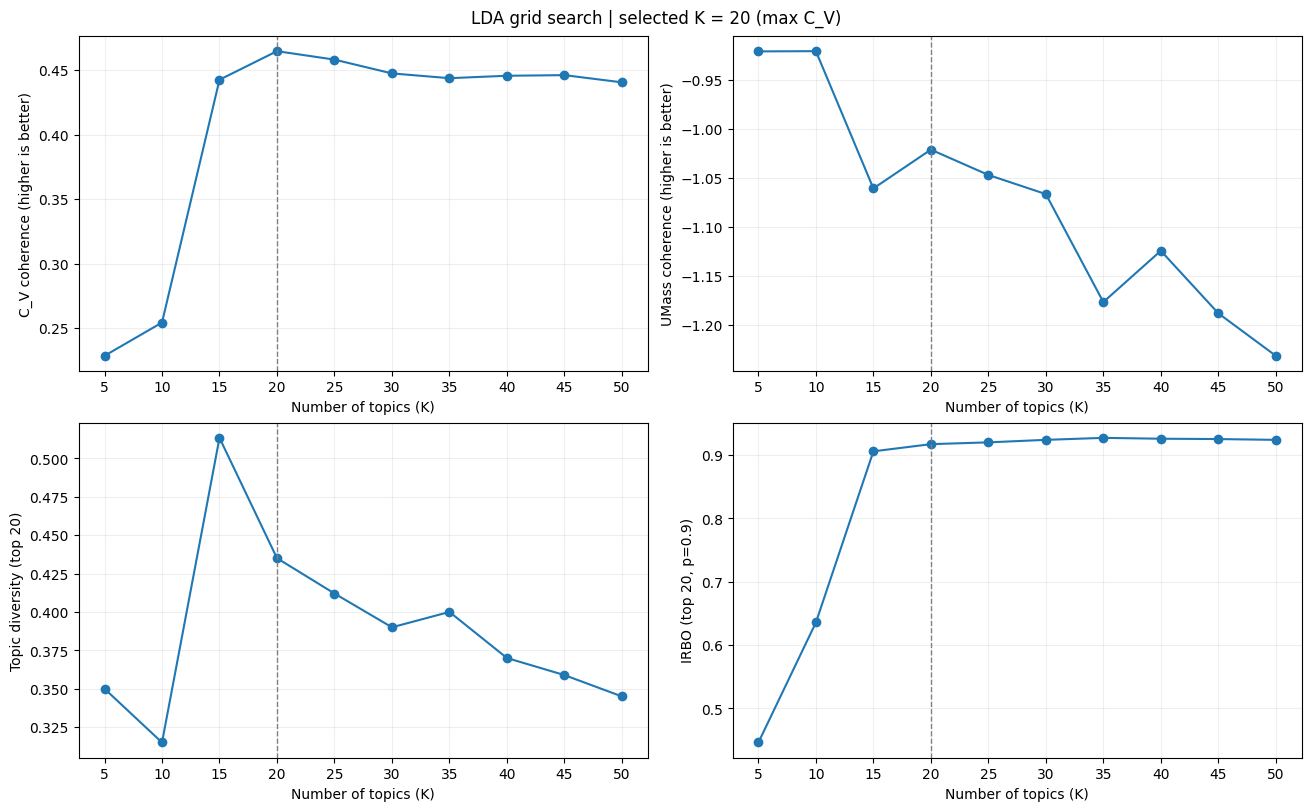

PosixPath('/kaggle/working/lda_fintechnews/figures/lda_model_selection.png')

In [8]:
def save_figure(fig, filename):
    path = FIG_DIR / filename
    fig.savefig(path, dpi=PLOT_DPI, bbox_inches="tight")
    if SHOW_PLOTS:
        display(fig)
    plt.close(fig)
    return path

plots = [
    ("c_v", "C_V coherence (higher is better)"),
    ("u_mass", "UMass coherence (higher is better)"),
    ("topic_diversity", "Topic diversity (top 20)"),
    ("irbo", "IRBO (top 20, p=0.9)"),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
for ax, (metric, label) in zip(axes.flat, plots):
    ax.plot(scores["n_topics"], scores[metric], marker="o")
    ax.axvline(best_k, color="gray", linestyle="--", linewidth=1)
    ax.set(xlabel="Number of topics (K)", ylabel=label)
    ax.set_xticks(scores["n_topics"])
    ax.grid(alpha=0.2)
fig.suptitle(f"LDA grid search | selected K = {best_k} (max C_V)")
save_figure(fig, "lda_model_selection.png")

## 8. Visualization: top-word probabilities and word clouds (all topics)

For **every** topic of the selected LDA model, export ranked term probabilities and a reproducible Word Cloud. Images are grouped into pages of 6 to keep the notebook readable. Individual Word Clouds are also saved in `figures/wordclouds/`.

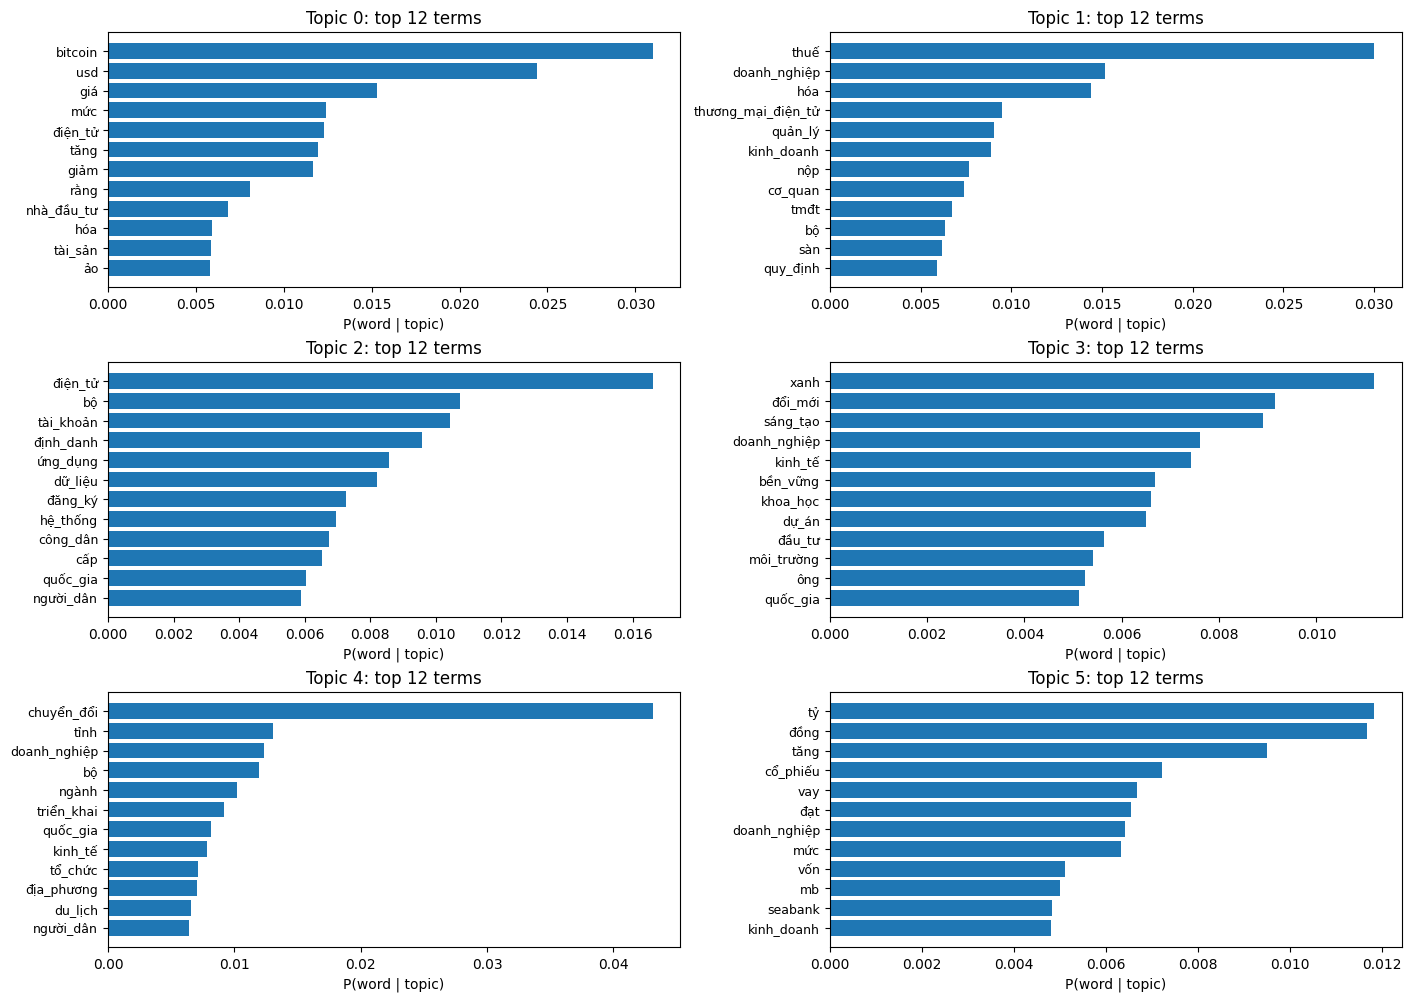

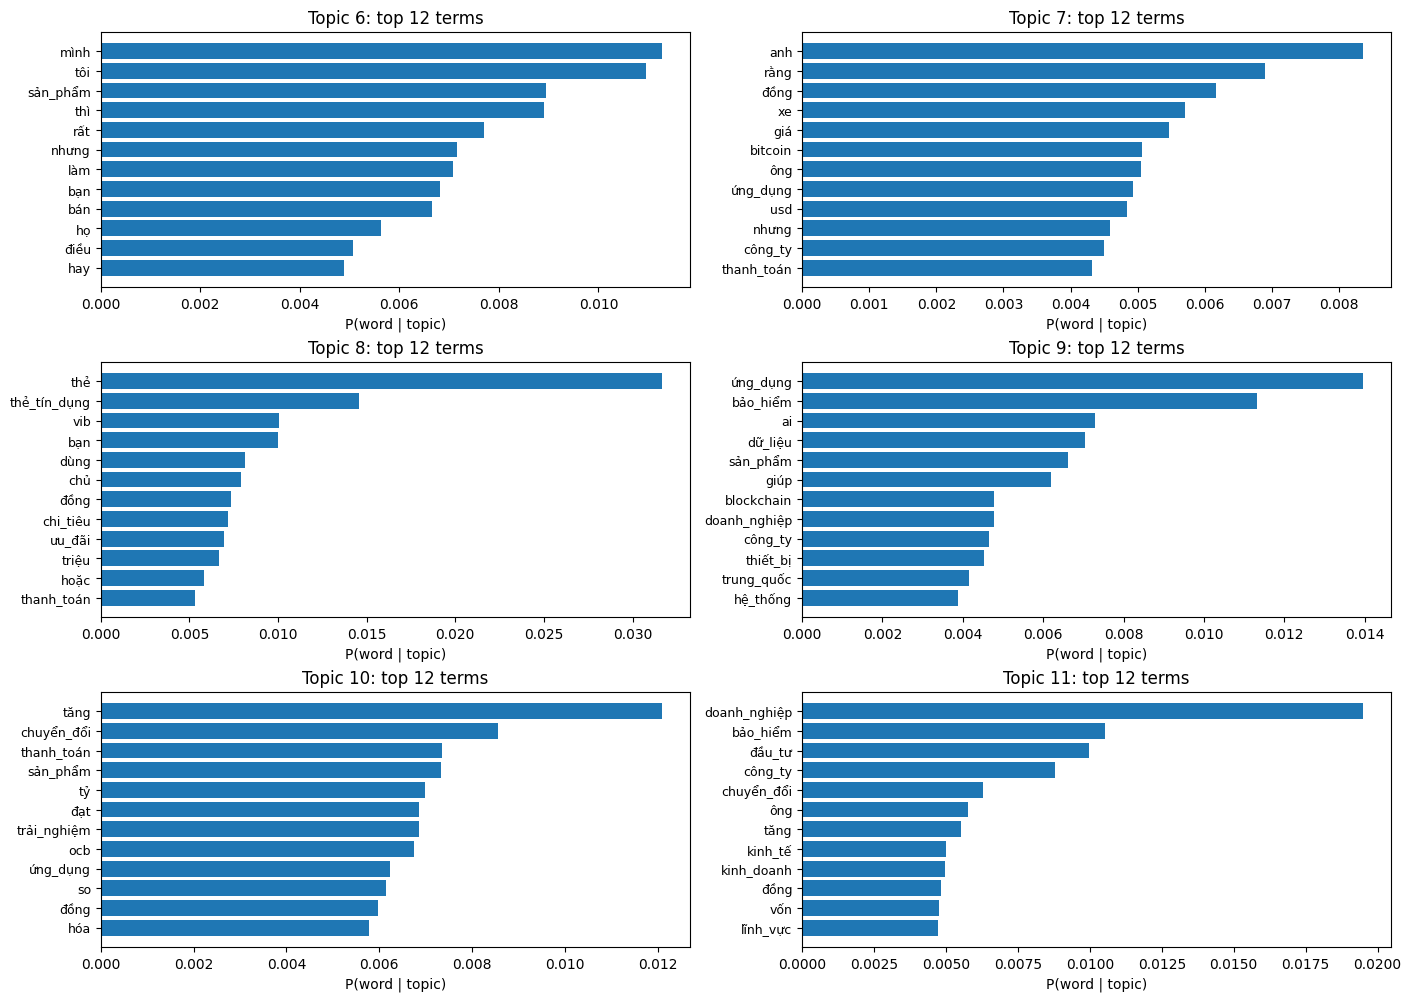

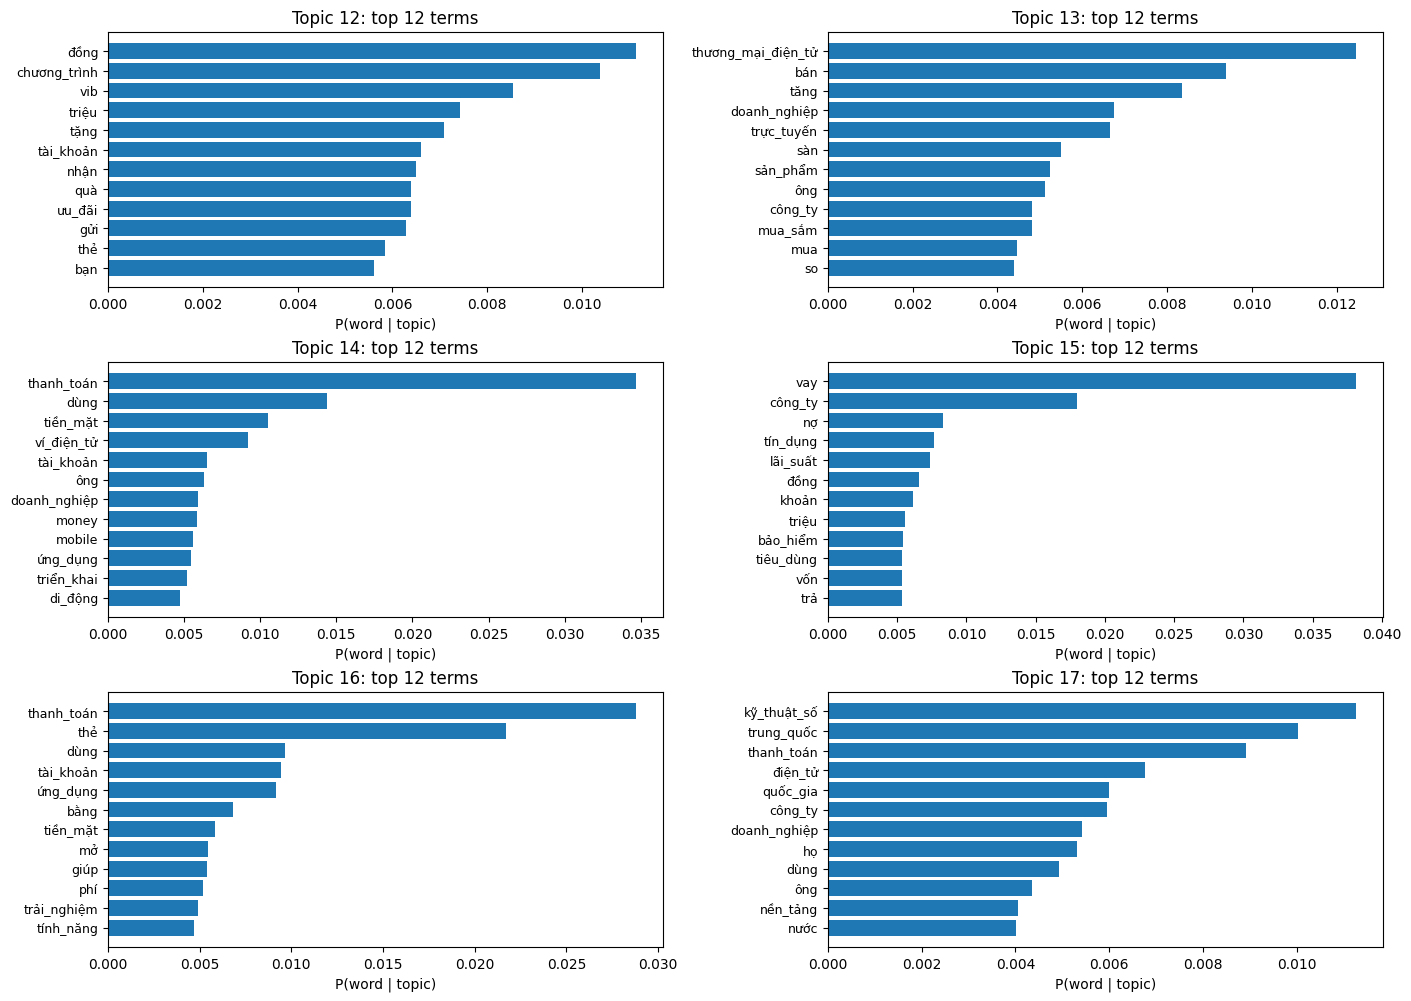

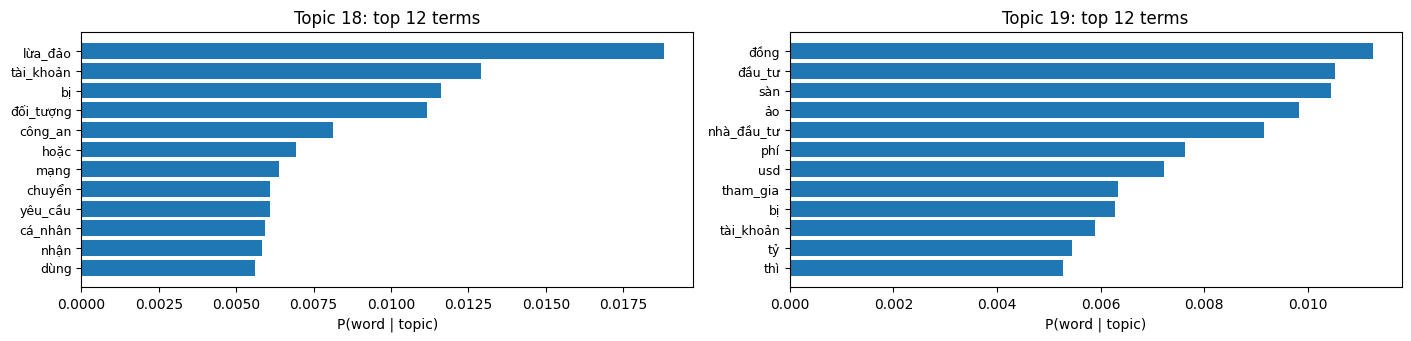

In [9]:
if not (1 <= TOP_PLOT_WORDS <= TOP_WORDS):
    raise ValueError("TOP_PLOT_WORDS must be between 1 and TOP_WORDS")
if TOPICS_PER_PAGE < 1:
    raise ValueError("TOPICS_PER_PAGE must be positive")

for start in range(0, best_k, TOPICS_PER_PAGE):
    ids = list(range(start, min(start + TOPICS_PER_PAGE, best_k)))
    rows = math.ceil(len(ids) / 2)
    fig, axs = plt.subplots(rows, 2, figsize=(14, 3.3 * rows), squeeze=False, layout="constrained")
    for ax, topic_id in zip(axs.flat, ids):
        top = best_model.show_topic(topic_id, topn=TOP_PLOT_WORDS)
        words, weights = zip(*reversed(top))
        ax.barh(words, weights)
        ax.set(xlabel="P(word | topic)", title=f"Topic {topic_id}: top {TOP_PLOT_WORDS} terms")
        ax.tick_params(axis="y", labelsize=9)
    for ax in list(axs.flat)[len(ids):]:
        ax.axis("off")
    page = start // TOPICS_PER_PAGE + 1
    save_figure(fig, f"lda_topic_term_bars_page_{page:02d}.png")

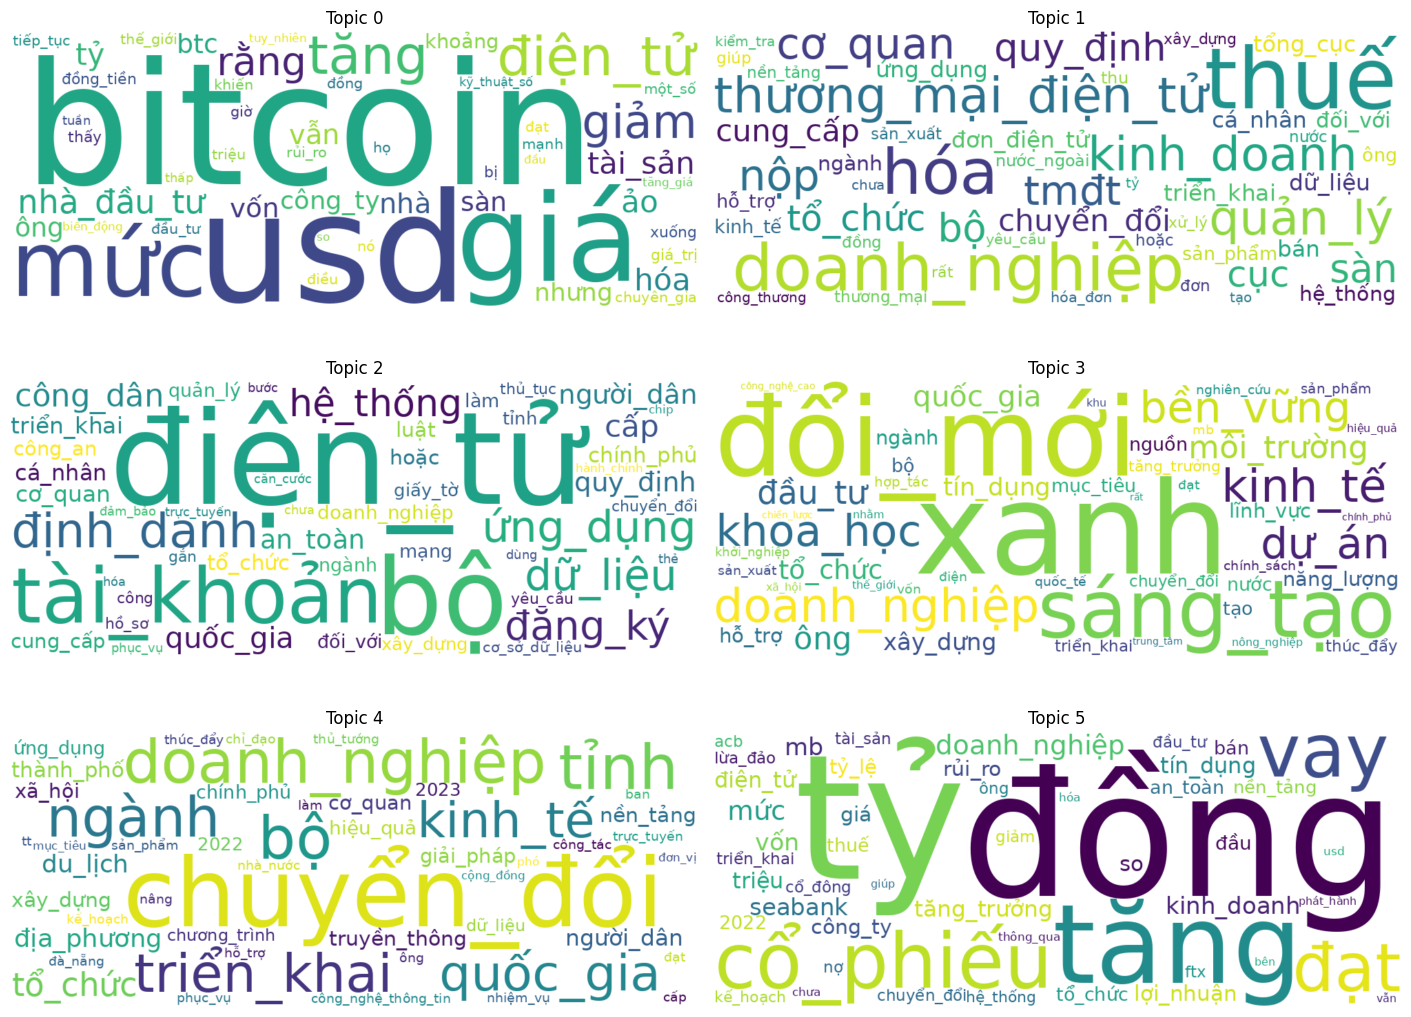

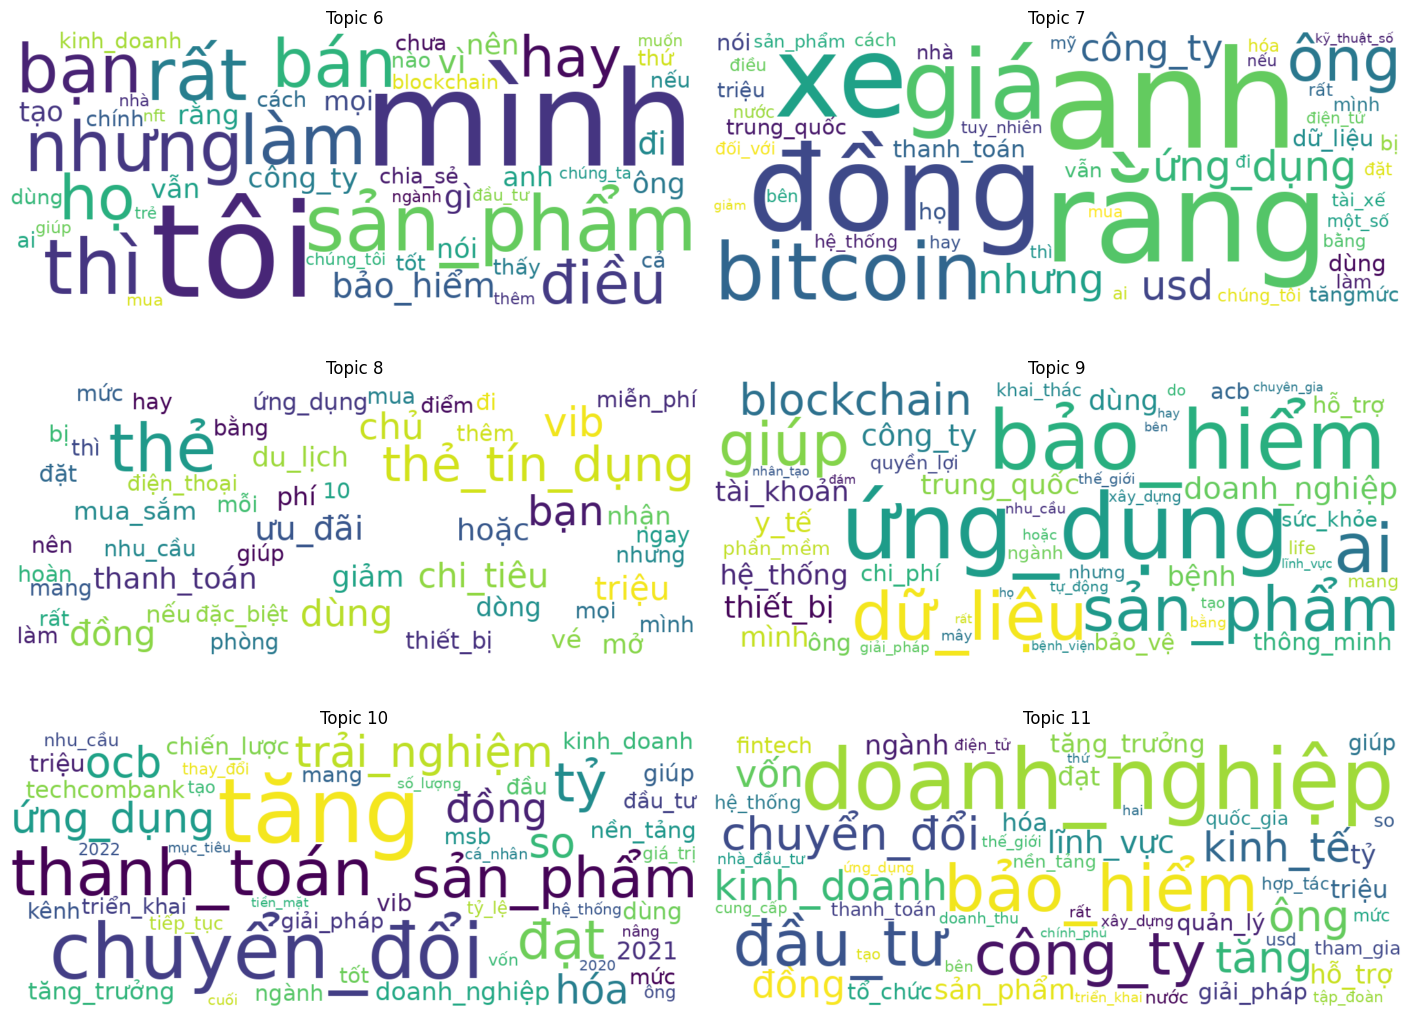

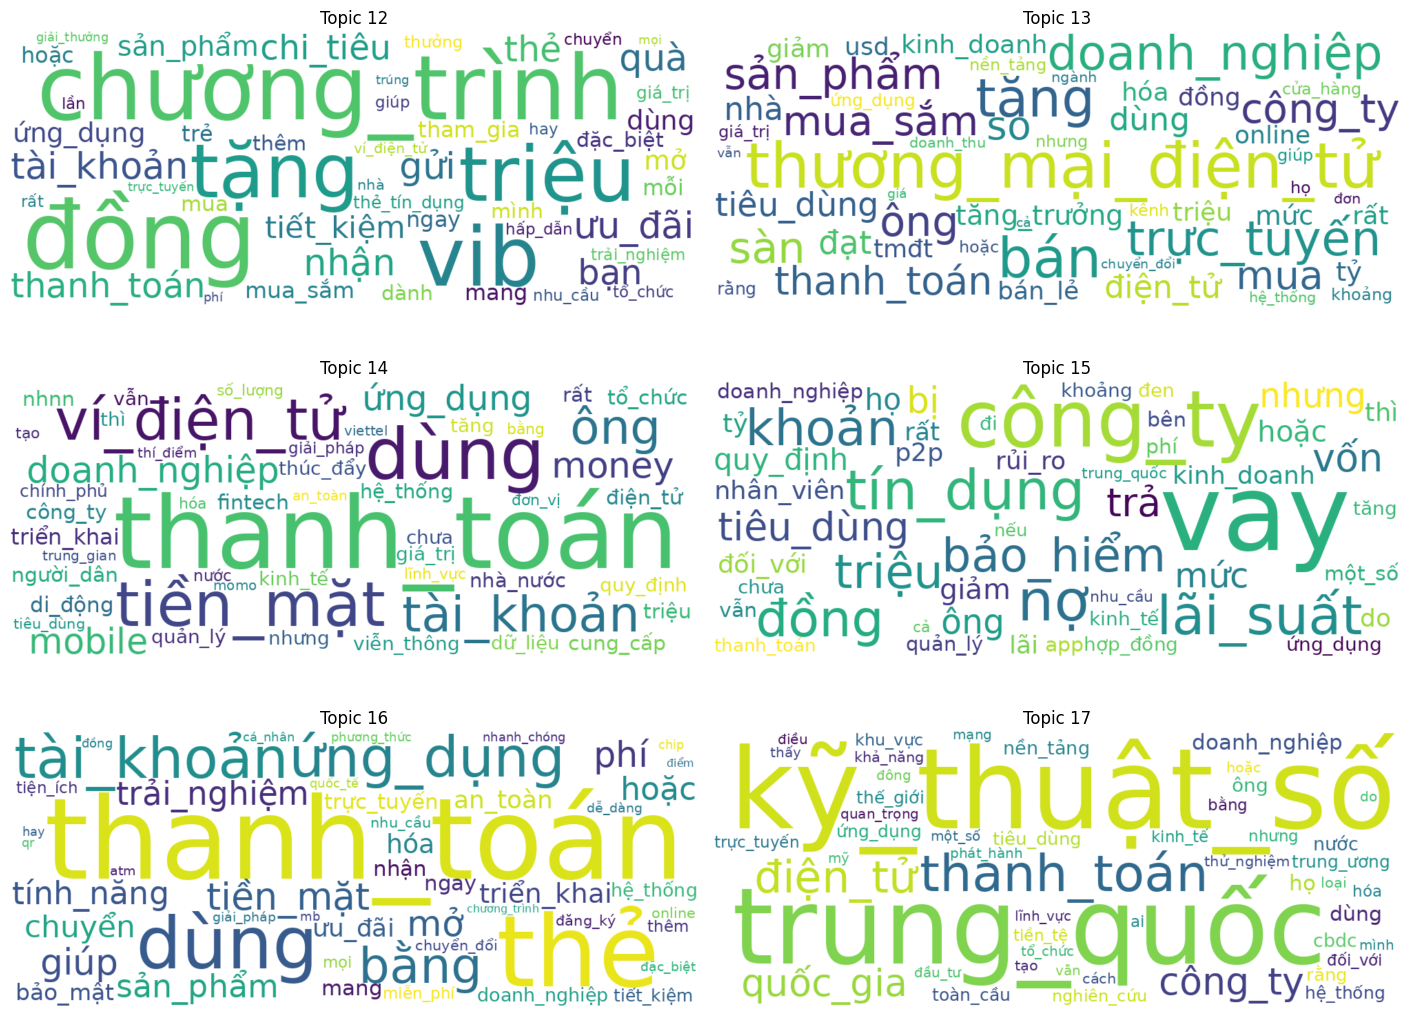

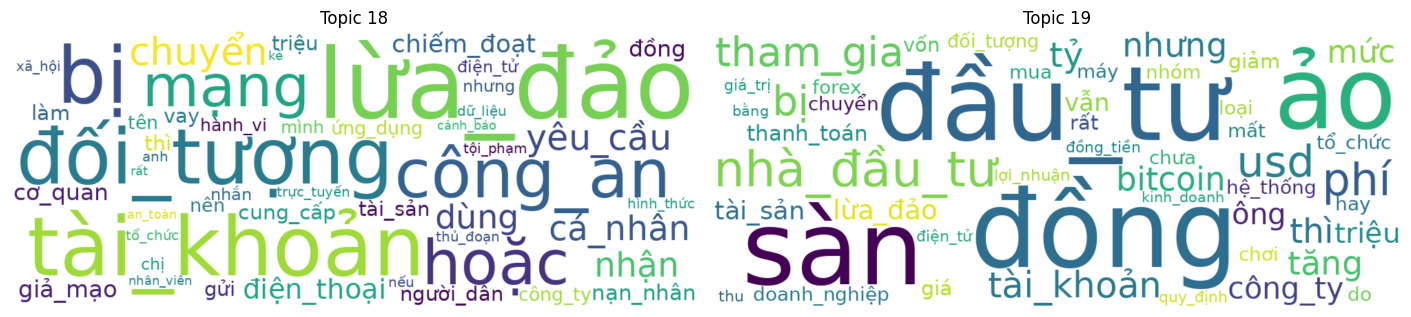

In [10]:
cloud_dir = FIG_DIR / "wordclouds"
cloud_dir.mkdir(parents=True, exist_ok=True)
font_path = font_manager.findfont("DejaVu Sans")  # handles Vietnamese diacritics

for start in range(0, best_k, TOPICS_PER_PAGE):
    ids = list(range(start, min(start + TOPICS_PER_PAGE, best_k)))
    rows = math.ceil(len(ids) / 2)
    fig, axs = plt.subplots(rows, 2, figsize=(14, 3.5 * rows), squeeze=False, layout="constrained")
    for ax, topic_id in zip(axs.flat, ids):
        frequencies = dict(best_model.show_topic(topic_id, topn=WORDCLOUD_WORDS))
        wc = WordCloud(
            width=1000, height=400, font_path=font_path,
            background_color="white", collocations=False,
            prefer_horizontal=1.0, random_state=SEED + topic_id
        ).generate_from_frequencies(frequencies)
        wc.to_file(str(cloud_dir / f"lda_topic_{topic_id:02d}.png"))
        ax.imshow(wc, interpolation="bilinear")
        ax.set_title(f"Topic {topic_id}")
        ax.axis("off")
    for ax in list(axs.flat)[len(ids):]:
        ax.axis("off")
    page = start // TOPICS_PER_PAGE + 1
    save_figure(fig, f"lda_wordclouds_page_{page:02d}.png")

## 9. Visualization: topic prevalence and time trends

Two prevalence measures are deliberately distinct: **dominant-topic share** (argmax assignment) and **mean mixture weight** (soft prevalence). When a valid publication-date column is present, also plot mean topic probabilities per period and write the per-period values to CSV.

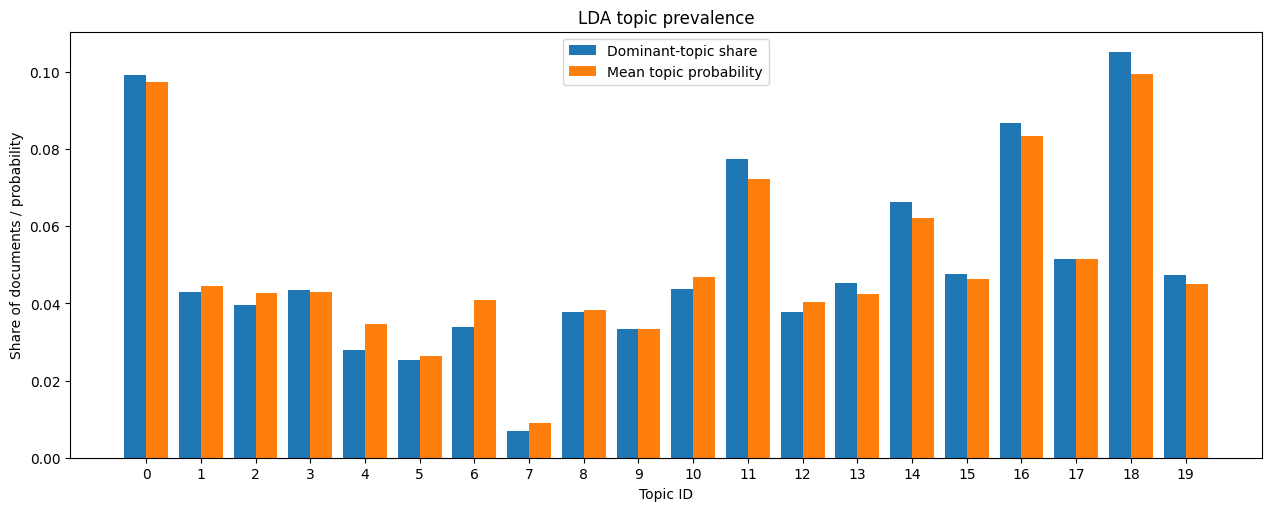

,topic_id,dominant_document_count,dominant_document_share,mean_topic_probability
0,0,838,0.099289,0.097467
1,1,363,0.043009,0.044401
2,2,335,0.039692,0.042678
3,3,368,0.043602,0.042907
4,4,235,0.027844,0.034568
5,5,213,0.025237,0.026280
6,6,285,0.033768,0.040879
7,7,58,0.006872,0.009080
8,8,320,0.037915,0.038271
9,9,282,0.033412,0.033328


In [11]:
topic_prevalence = pd.DataFrame({
    "topic_id": np.arange(best_k),
    "dominant_document_count": np.bincount(theta.argmax(axis=1), minlength=best_k),
    "dominant_document_share": np.bincount(theta.argmax(axis=1), minlength=best_k) / len(theta),
    "mean_topic_probability": theta.mean(axis=0)
})
topic_prevalence.to_csv(OUTPUT_DIR / "lda_topic_prevalence.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(max(10, best_k * 0.43 + 4), 5), layout="constrained")
x = np.arange(best_k)
ax.bar(x - 0.2, topic_prevalence["dominant_document_share"], width=0.4,
       label="Dominant-topic share")
ax.bar(x + 0.2, topic_prevalence["mean_topic_probability"], width=0.4,
       label="Mean topic probability")
ax.set(xlabel="Topic ID", ylabel="Share of documents / probability", title="LDA topic prevalence")
ax.set_xticks(x)
ax.legend()
save_figure(fig, "lda_topic_prevalence.png")
display(topic_prevalence)

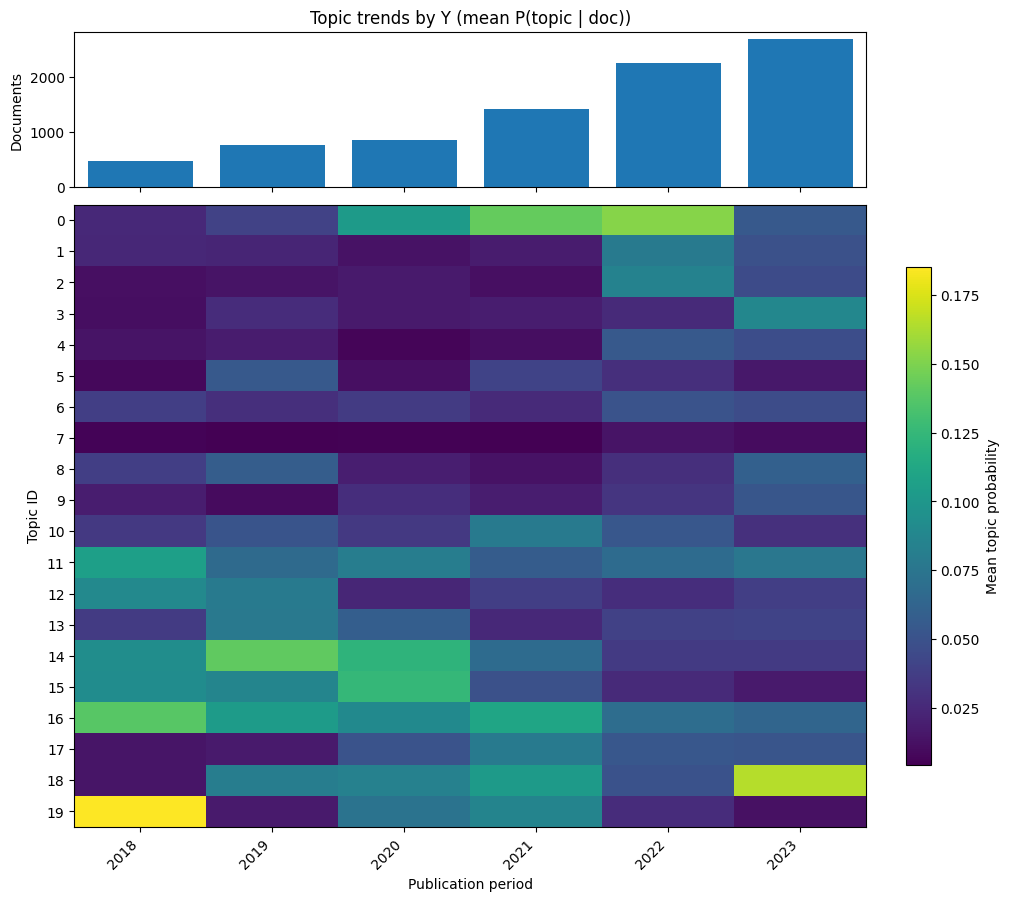

Temporal plot: 8,440 valid dates, 6 periods


In [12]:
if DATE_COLUMN and DATE_COLUMN in df.columns:
    dates = pd.to_datetime(df[DATE_COLUMN].astype(str).str.strip(),
                           errors="coerce", format="mixed", dayfirst=DAYFIRST)
    good = dates.notna().to_numpy()
    if good.sum() >= 2:
        period = dates.loc[good].dt.to_period(TIME_FREQ).astype(str).to_numpy()
        temporal = pd.DataFrame(theta[good], columns=[f"topic_{i}" for i in range(best_k)])
        temporal.insert(0, "period", period)
        by_period = temporal.groupby("period", sort=True).mean()
        counts = temporal.groupby("period", sort=True).size()
        trend_csv = by_period.copy()
        trend_csv.insert(0, "n_documents", counts)
        trend_csv.to_csv(OUTPUT_DIR / "lda_topic_trends.csv", encoding="utf-8-sig")

        fig, (ax_count, ax_heat) = plt.subplots(
            2, 1, figsize=(max(10, 0.55 * len(by_period) + 4), max(6, 0.27 * best_k + 3.5)),
            gridspec_kw={"height_ratios": [1, 4]}, sharex=True, layout="constrained"
        )
        locations = np.arange(len(by_period))
        ax_count.bar(locations, counts.to_numpy())
        ax_count.set(ylabel="Documents", title=f"Topic trends by {TIME_FREQ} (mean P(topic | doc))")
        heat = ax_heat.imshow(by_period.to_numpy().T, aspect="auto", interpolation="nearest")
        ax_heat.set(xlabel="Publication period", ylabel="Topic ID")
        ax_heat.set_yticks(np.arange(best_k))
        ax_heat.set_xticks(locations, by_period.index.tolist(), rotation=45, ha="right")
        fig.colorbar(heat, ax=ax_heat, shrink=0.8, label="Mean topic probability")
        save_figure(fig, "lda_topic_trends.png")
        print(f"Temporal plot: {good.sum():,} valid dates, {len(by_period)} periods")
    else:
        print("Skipping temporal plot: fewer than two parseable publication dates")
else:
    print("Skipping temporal plot: DATE_COLUMN is missing or disabled")

## 10. Interactive LDA visualization: pyLDAvis

Inspect **inter-topic distances** and **salient/relevant terms**. The output is embedded below and independently saved as `lda_pyLDAvis.html`. `sort_topics=False` preserves Gensim topic numbering (pyLDAvis labels may be one-based). Generating the visualization can take additional CPU/RAM.

In [13]:
import pyLDAvis
import pyLDAvis.gensim_models
from IPython.display import HTML

prepared = pyLDAvis.gensim_models.prepare(
    best_model, corpus, dictionary, sort_topics=False, n_jobs=1
)
pyldavis_path = OUTPUT_DIR / "lda_pyLDAvis.html"
pyLDAvis.save_html(prepared, str(pyldavis_path))
print("Interactive visualization:", pyldavis_path)
if SHOW_PLOTS:
    display(HTML(pyLDAvis.prepared_data_to_html(prepared)))

Interactive visualization: /kaggle/working/lda_fintechnews/lda_pyLDAvis.html


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 11. Export outputs and reproducibility manifest

In [14]:
scores.to_csv(OUTPUT_DIR / "lda_grid_metrics.csv", index=False, encoding="utf-8-sig")
topic_terms.to_csv(OUTPUT_DIR / "lda_topic_terms.csv", index=False, encoding="utf-8-sig")
assignments.to_csv(OUTPUT_DIR / "lda_document_topics.csv", index=False, encoding="utf-8-sig")
best_model.save(str(OUTPUT_DIR / "lda_best.model"))
dictionary.save(str(OUTPUT_DIR / "lda_dictionary.gensim"))
manifest = {"dataset_name": DATASET_NAME, "data_path": str(DATA_PATH),
            "n_documents": len(df), "corpus_sha256": corpus_hash, "config_sha256": run_hash,
            "selected_k": best_k, "k_values": K_VALUES, "config": config,
            "python": platform.python_version(),
            "packages": {p: version(p) for p in ["gensim", "underthesea", "numpy", "pandas"]},
            "plots": sorted(str(p.relative_to(OUTPUT_DIR)) for p in FIG_DIR.rglob("*.png")),
            "interactive_html": str(pyldavis_path.relative_to(OUTPUT_DIR)),
            "visualization_options": {
                "show_plots": SHOW_PLOTS, "plot_dpi": PLOT_DPI,
                "top_plot_words": TOP_PLOT_WORDS, "topics_per_page": TOPICS_PER_PAGE,
                "wordcloud_words": WORDCLOUD_WORDS, "time_freq": TIME_FREQ,
                "dayfirst": DAYFIRST
            },
            "note": "Determinism assumes identical input row order, dependency versions, and CPU environment."}
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("Saved results to:", OUTPUT_DIR)
print("Static visualizations:", len(manifest["plots"]), "PNG files")
print("pyLDAvis HTML:", pyldavis_path.name)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Saved results to: /kaggle/working/lda_fintechnews
Static visualizations: 31 PNG files
pyLDAvis HTML: lda_pyLDAvis.html


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Notes on scientific reproducibility

1. LDA uses `LdaModel` (single process), fixed `random_state`, `update_every=0` and `eval_every=None`; multi-core asynchronous LDA may not reproduce exactly.
2. `alpha='auto'` and `eta='auto'` are learned hyperparameters, not fixed numeric priors. Record these settings alongside the model.
3. C_V is calculated on the same **unfiltered** reference tokens across all K; training vocabulary is filtered. Avoid dropping unmatched terms silently.
4. Topic Diversity and IRBO are *lexical* metrics; high values alone do not establish meaningful topics.
5. Comparing BERTopic and LDA requires identical documents, tokenization, top-N and reference corpus. BERTopic's original snippet used `vietnamese_tokens(doc)`; replace its definition with the same implementation as this notebook or load shared pretokenized texts.
6. This notebook does not claim bitwise reproducibility across different BLAS, OS or library versions. `run_manifest.json` records versions and fingerprints.

**References:** Röder et al. (2015), *Exploring the Space of Topic Coherence Measures*; Mimno et al. (2011), *Optimizing Semantic Coherence in Topic Models*; Dieng et al. (2020), *Topic Modeling in Embedding Spaces*; Bianchi et al. (2021), *Pre-training is a Hot Topic*; Webber et al. (2010), *A Similarity Measure for Indefinite Rankings*.

**Visual sanity checks:** Verify `figures/lda_model_selection.png`, the `lda_topic_term_bars_page_*.png` pages, all `figures/wordclouds/lda_topic_*.png` files, `lda_topic_prevalence.png`, optional `lda_topic_trends.png`, and `lda_pyLDAvis.html`. Topic IDs in all PNGs and tables are **zero-based**; pyLDAvis may display them as 1-based labels. Temporal means represent **soft topic probabilities**, not hard article counts.


In [ ]:
import shutil
from IPython.display import FileLink, display

zip_path = shutil.make_archive(
    "/kaggle/working/lda_fintechnews",
    "zip",
    root_dir=OUTPUT_DIR
)

display(FileLink(zip_path))